# Full training: the winning recipe on every training photo

The background arms (notebook 18) chose a recipe on the 13,925-photo experiment subset. This notebook
trains that recipe on every training photo we may use, 49,782 photos of all 184 species, for 30 epochs,
and scores it the way M3 scored its final model: verdict thresholds fitted on the calibration photos,
scores on the validation photos, the scenery test, and a comparison with B1, the published SnakeCLEF
model, on the 62 species it knows.

A Kaggle GPU session can wait hours in the queue, so everything happens in one session:

1. **the front end**: M3's detector and U-Net give a box and a mask to the training photos that M3's
   front-end file does not cover (about 39,000 of them);
2. **a smoke pass**: every step below, on 500 training photos for one epoch, with its checks;
3. **the full pass**: the very same functions on all 49,782 photos for 30 epochs. At its first
   evaluation the session projects its own length and stops if that is over 11 hours.

The Kaggle runner executes every cell even after one fails (so the notebook is always saved with its
outputs). So that a failure still stops what comes after it, every checking cell records that it
finished: the smoke pass starts only when all of them did, the full pass only when the smoke passed,
and the non-snake cell only when the full pass finished. A failure in the inputs or the smoke stops
the session's GPU work within minutes.

The last cell scores the non-snake test photos once, when the non-snake set and the gate picked in
notebook 20 can be read; otherwise it is skipped, and it can run later on its own.

It needs the cleaned photos, the experiment subset and the SAM masks (shared with the team), M3's
front-end weights and file, M3's final run and B1's saved predictions (the baselines notebook; B1 is
not run again). `ACCOUNT` names the Kaggle account the session runs on, since a teammate's session
reads private copies of the files that only our account owns. Run it on Kaggle with a T4 GPU and
internet on: about 7 hours (front end under an hour, smoke pass about 20 minutes, training about 5
hours, scoring under an hour). It writes the run folder `M4_FULL/`, the result files under `full/`
(they go to `results/m4/full/` in the repo) and the smoke pass under `smoke/` and `M4_FULL_smoke/`.

In [1]:
import time
STARTED = time.time()  # the session's own clock, for the time check

%pip install -q timm==1.0.31 albumentations==2.0.8 scikit-learn==1.9.1
%pip install -q ultralytics==8.4.202 segmentation-models-pytorch==0.6.0
import hashlib, json, os, shutil, sys, tempfile, traceback, warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from types import SimpleNamespace

os.environ.update(NO_ALBUMENTATIONS_UPDATE="1", YOLO_VERBOSE="False",
                  HF_HUB_DISABLE_PROGRESS_BARS="1", TQDM_DISABLE="1")
warnings.filterwarnings("ignore")

import kagglehub, torch, yaml
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

ON_KAGGLE = Path("/kaggle/working").exists()
if ON_KAGGLE:  # the repository is unpacked next to the notebook or attached as a dataset
    REPO = next(p for p in (Path("/kaggle/working/repo"), Path("/kaggle/input/serpentguard-code"))
                if (p / "src").exists())
else:
    REPO = Path("..").resolve()
sys.path.insert(0, str(REPO / "src"))
WORK = Path("/kaggle/working") if ON_KAGGLE else Path("work_full")
SCRATCH = Path("/kaggle/tmp/full_training") if ON_KAGGLE else WORK / "tmp"  # big files, not saved

from serpentguard import data, front_end, robustness
from serpentguard.decide import decision_report, load_outputs
from serpentguard.metrics import (BOOTSTRAP_RESAMPLES, BOOTSTRAP_SEED, assert_no_test_paths,
                                  class_tables, paired_difference_ci, photographer_groups, softmax,
                                  species_report, write_json)
from serpentguard.train import (CALIBRATION_OUTPUTS, VAL_OUTPUTS, load_checkpoint, predict,
                                save_outputs, train)

ACCOUNT = 'puneet'
WINNER_CONFIG = 'results/m4/arms/A1/config.yaml'
EPOCHS = 30
SMOKE_PHOTOS, SMOKE_EPOCHS = 500, 1
TIME_LIMIT_HOURS = 11
RUN_ID = "M4_FULL"
PASSED = set()  # the checking cells that finished; a later pass starts only when all did
SMOKE_PASSED = FULL_PASSED = False
for folder in (WORK, SCRATCH):
    folder.mkdir(parents=True, exist_ok=True)
print(f"{torch.cuda.device_count()} GPU(s), account {ACCOUNT}; results go to {WORK}")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
2 GPU(s), account puneet; results go to /kaggle/working


## 1. The inputs

The cleaned photos, the experiment subset and the SAM masks are shared with the team. M3's front end
(notebook 13's detector and U-Net, and its `frontend_preds.csv` with the masks it wrote), M3's final
run and B1's saved predictions are private to our account; a teammate's session reads byte-identical
private copies on its own account. Every file is checked by its SHA-256, so all three accounts train
from the same inputs.

In [2]:
ACCOUNTS = {"puneet": "puneetbajajiitm", "jayesh": "jayeshbansal497", "vikas": "vikas25s"}
SHARED = "puneetbajajiitm"
M3_FRONT_END = "puneetbajajiitm/sg-m3-frontends"  # notebook 13's run
CHECKSUMS = {  # SHA-256 of the files every account must read
    "detector": "099b36bd8271c328b60be8152161f74558a0083ebe4e6fec1f558e7c0951c5b0",
    "unet": "f7646444ec409614e992cd7a112a1c2c47fd81a1dc62afea54f50f83664abf3f",
    "m3_preds": "9dcc0576eb1c60d3e767ba9ca3c34a6a1b92b6b01946e377042dee1b1287b9e3",
    "b1": "f701e21261d690d9e3d7cb61b44ace3dc05660f82d4d977db2b92149f3e93251"}
assert ACCOUNT in ACCOUNTS, f"ACCOUNT must be one of {list(ACCOUNTS)}"
OWNER = ACCOUNTS[ACCOUNT]


def dataset(handle):
    return Path(kagglehub.dataset_download(handle))


def kernel_output(handle):
    return Path(kagglehub.notebook_output_download(handle))


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def found(root, pattern):
    return next(Path(root).rglob(pattern))


DATA = dataset(f"{SHARED}/serpentguard-indian-snakes-clean")
SUBSET = dataset(f"{SHARED}/serpentguard-m3-subset") / "subset.csv"
MASKS = dataset(f"{SHARED}/serpentguard-sam-masks")
if ACCOUNT == "puneet":
    weights = m3_front_end = kernel_output(M3_FRONT_END)
else:
    weights = dataset(f"{OWNER}/serpentguard-m3-frontend-weights")
    m3_front_end = dataset(f"{OWNER}/serpentguard-m4-frontend-masks")
DETECTOR = found(weights, "D1/yolo26n-ft/detector.pt")
UNET = found(weights, "S1/unet/segmenter.pt")
M3_PREDS = found(m3_front_end, front_end.PREDS_FILE).parent
B1_DIR = found(dataset(f"{OWNER}/serpentguard-m3-b1-predictions"), "predictions.npz").parent
M3_RUN = found(dataset(f"{OWNER}/serpentguard-m3-run-final"), VAL_OUTPUTS).parent
for name, path in (("detector", DETECTOR), ("unet", UNET),
                   ("m3_preds", M3_PREDS / front_end.PREDS_FILE),
                   ("b1", B1_DIR / "predictions.npz")):
    assert sha256(path) == CHECKSUMS[name], f"{path} is not the {name} file this notebook expects"

ids = {"obs_id": str, "photo_id": str, "observer_id": str}
metadata = pd.read_csv(DATA / "metadata.csv", dtype=ids, low_memory=False)
classes = pd.read_csv(DATA / "classes.csv")
subset = pd.read_csv(SUBSET, dtype=ids)
m3_preds = pd.read_csv(M3_PREDS / front_end.PREDS_FILE, keep_default_na=False)
taxa = class_tables(classes)
print(f"{len(metadata):,} photos of {len(classes)} species; M3's front-end file has "
      f"{len(m3_preds):,} rows; every checksum matches")
PASSED.add("inputs")

121,566 photos of 184 species; M3's front-end file has 39,526 rows; every checksum matches


### B1's saved predictions

B1 can name only 62 of our 184 species, so the comparison later is on photos of those 62. Before any
GPU time we check that B1's saved predictions still give M3's recorded B1 scores, on all validation
photos and on the photos uploaded from 2022 on, which B1 cannot have trained on.

Two macro-F1s are used. The headline one, which G3 is judged on, is macro-F1 over the 62 species
computed on the photos of those species only (11,931 photos in the 2022 slice): each species' F1 from
the predictions on those photos, then averaged. M3's comparison counted precision over every photo of
the slice, including photos of species B1 can't know, which lowers B1's precision; that one is
reported next to it as "M3's whole-slice definition", so the numbers line up with M3's report.

In [3]:
SLICE_FROM = "2022-01-01"  # created_at is compared as text, as in the baselines notebook
SLICE_PHOTOS, B1_SPECIES = 13_947, 62
SLICES = {"full_validation": "all validation photos", "upload_2022_slice": "uploaded from 2022"}

b1 = load_outputs(B1_DIR / "predictions.npz")
b1_metrics = json.loads((B1_DIR / "final_metrics.json").read_text())
m3_comparison = json.loads((B1_DIR / "compare_b1_shared.json").read_text())
B1_CLASSES = np.array(sorted(b1_metrics["coverage"]["covered_class_ids"]))
assert len(B1_CLASSES) == B1_SPECIES == m3_comparison["shared_classes"]


def uploaded_2022(paths):
    created = pd.DataFrame({"path": paths}).merge(metadata[["path", "created_at"]], on="path",
                                                  how="left", validate="many_to_one")
    assert created["created_at"].notna().all(), "a photo has no upload date"
    return created["created_at"].astype(str).ge(SLICE_FROM).to_numpy()


def top1(y_true, pred):
    return float(np.mean(y_true == pred))


def macro_f1(y_true, pred):
    """The F1 of each B1 species with a photo here, averaged; precision counts every photo given."""
    present = np.intersect1d(B1_CLASSES, y_true)
    return float(f1_score(y_true, pred, labels=present, average="macro", zero_division=0))


b1_pred = b1["probs"].argmax(axis=1)
b1_slices = {"full_validation": np.ones(len(b1_pred), dtype=bool),
             "upload_2022_slice": uploaded_2022(b1["paths"])}
assert b1_slices["upload_2022_slice"].sum() == SLICE_PHOTOS
b1_check = {}
for name, keep in b1_slices.items():
    shared_rows = keep & np.isin(b1["labels"], B1_CLASSES)
    recorded = m3_comparison[name]["b1"]
    b1_check[name] = {"photos": int(shared_rows.sum()), "recorded photos": recorded["photos"],
                      "top-1": top1(b1["labels"][shared_rows], b1_pred[shared_rows]),
                      "recorded top-1": recorded["top1"],
                      "macro-F1, whole slice": macro_f1(b1["labels"][keep], b1_pred[keep]),
                      "recorded macro-F1": recorded["macro_f1"]}
    row = b1_check[name]
    assert row["photos"] == row["recorded photos"], f"{name}: another set of photos"
    assert abs(row["top-1"] - row["recorded top-1"]) < 1e-9, f"{name}: B1's top-1 moved"
    assert abs(row["macro-F1, whole slice"] - row["recorded macro-F1"]) < 1e-9, name
PASSED.add("B1 check")
pd.DataFrame(b1_check).T.rename(index=SLICES)

,photos,recorded photos,top-1,recorded top-1,"macro-F1, whole slice",recorded macro-F1
all validation photos,14610.0,14610.0,0.801232,0.801232,0.652999,0.652999
uploaded from 2022,11931.0,11931.0,0.788031,0.788031,0.636816,0.636816


## 2. The training list

The training photos, minus every photo by a calibration photographer (the thresholds are fitted on
their photos, so the model must never see them), capped as in M3 at 50 photos per photographer per
species and 1,000 per species. It must come to 49,782 photos of all 184 species, and capping the list
again, as training does, must keep every photo. The smoke pass trains on the first 500 of them.

In [4]:
FULL_PHOTOS, FULL_SPECIES, SUBSET_FINGERPRINT = 49_782, 184, "40196d19a68e"

fingerprint = hashlib.sha256("\n".join(sorted(subset["path"])).encode()).hexdigest()
assert fingerprint.startswith(SUBSET_FINGERPRINT), "this is not the experiment subset"
full = data.cap_train(data.full_train_rows(metadata, subset))
train_split = metadata[metadata["split"] == "train"]
listed = train_split[train_split["path"].isin(full["path"])]
calibration = data.calibration_set(train_split, subset)
assert len(full) == FULL_PHOTOS and full["species"].nunique() == FULL_SPECIES, "not the full list"
assert full["path"].is_unique and len(listed) == FULL_PHOTOS, "a listed photo isn't for training"
assert len(data.cap_train(listed)) == FULL_PHOTOS, "capping the list again must keep every photo"
assert not set(full["observer_id"]) & set(calibration["observer_id"]), "a calibration photographer"
unknown_pool = metadata[metadata["split"] == "unknown_pool"]
SCORED_PHOTOS = {"val": int((metadata["split"] == "val").sum()), "calibration": len(calibration),
                 "unknown": len(data.unknown_split(unknown_pool)[0])}
LISTS = {"smoke": WORK / "smoke" / "smoke_train.csv", "full": WORK / "full" / "full_train.csv"}
for name, rows in (("smoke", full.head(SMOKE_PHOTOS)), ("full", full)):
    LISTS[name].parent.mkdir(parents=True, exist_ok=True)
    rows[["path"]].to_csv(LISTS[name], index=False)
lacking = ~full["path"].isin(m3_preds["path"])
print(f"{FULL_PHOTOS:,} photos of {FULL_SPECIES} species by {full['observer_id'].nunique():,} "
      f"photographers; {lacking.sum():,} lack a front-end row (the smoke's "
      f"{SMOKE_PHOTOS}: {lacking[:SMOKE_PHOTOS].sum()}); scored sets {SCORED_PHOTOS}")
PASSED.add("training list")

49,782 photos of 184 species by 6,213 photographers; 38,853 lack a front-end row (the smoke's 500: 410); scored sets {'val': 17151, 'calibration': 7999, 'unknown': 451}


## 3. The recipe

Both passes use the winning arm's `config.yaml` (committed with the arms under
`results/m4/arms/<arm>/`; `WINNER_CONFIG` names it) with three changes: the run's own name, its
training list in place of the subset, and its epochs (30 for the full pass instead of the arm's 20: M3's
best epoch came at 18 of 20, and there is 3.6 times as much data). Everything else (encoder, losses,
learning rate, front end, which masks the swap uses, how often it swaps) stays as the arm trained it.
The subset is still read, because it defines the calibration photos.

When the recipe swaps scenery, it needs notebook 18's scenery bank: 3,000 snake-free sceneries made
from the subset's training photos with their predicted masks. The bank is rebuilt here with the same
code, photos and seed, and its `bank.csv` fingerprint must match the one the arm recorded.

In [5]:
BANK = SCRATCH / "scenery_bank"
BANK_FROM = {"run_id": "scenery_bank", "front_end": "F1", "scenery_swap": 0.5,
             "mask_source": "predicted", "train_list": None, "scenery_bank": None}  # notebook 18's

if WINNER_CONFIG is None:
    raise ValueError("set WINNER_CONFIG to results/m4/arms/<arm>/config.yaml of notebook 18's pick")
winner_file = REPO / WINNER_CONFIG
winner = data.run_config(yaml.safe_load(winner_file.read_text()))
SWAPS = winner["scenery_swap"] > 0
if SWAPS:
    bank_frames = data.make_frames({**winner, **BANK_FROM}, DATA, MASKS, SUBSET, M3_PREDS)
    bank = data.build_scenery_bank(bank_frames["train"], BANK)
    bank_sha = sha256(BANK / data.BANK_FILE)
    arm_row = winner_file.parent / "arm_row.json"
    recorded = json.loads(arm_row.read_text()).get("bank_sha256") if arm_row.exists() else None
    assert recorded in (None, bank_sha), f"the bank differs from the arm's: {bank_sha}"
    print(f"scenery bank: {len(bank):,} sceneries of {bank['class_id'].nunique()} species; "
          f"bank.csv sha256 {bank_sha} "
          f"({'the arm recorded the same' if recorded else 'no arm record'})")


def recipe(run_id, train_list, epochs):
    """The winning arm's settings with this run's name, training list and epochs."""
    cfg = {**winner, "run_id": run_id, "train_list": str(train_list), "epochs": epochs}
    return {**cfg, "scenery_bank": str(BANK)} if SWAPS else cfg


full_cfg = recipe(RUN_ID, LISTS["full"], EPOCHS)
print(f"recipe from {WINNER_CONFIG} (run {winner['run_id']}): front end {winner['front_end']}, "
      f"scenery swap {winner['scenery_swap']} with {winner['mask_source']} masks, "
      f"seed {winner['seed']}")
PASSED.add("recipe")
pd.DataFrame({key: {"winning arm": winner[key], "full pass": full_cfg[key]}
              for key in full_cfg if full_cfg[key] != winner[key]}).T

scenery bank: 3,000 sceneries of 184 species; bank.csv sha256 2eed027132bfacf956e85895b29131fa09f845c5b60bfcfa58272a687544fa5e (the arm recorded the same)
recipe from results/m4/arms/A1/config.yaml (run M4_A1): front end F1, scenery swap 0.5 with sam masks, seed 1


,winning arm,full pass
run_id,M4_A1,M4_FULL
epochs,20,30
train_list,None,/kaggle/working/full/full_train.csv
scenery_bank,/kaggle/working/scenery_bank,/kaggle/tmp/full_training/scenery_bank


## 4. The steps of one pass

Each step is a function, so the smoke pass and the full pass run exactly the same code:

1. **front end**: M3's detector and U-Net run over the pass's training photos that M3's file lacks,
   with `front_end.extend_predictions`; M3's rows are kept byte for byte and the new rows follow;
2. **swap coverage**: which training photos have a usable mask for the scenery swap (the others are
   never swapped);
3. **training**, with the time check;
4. **reading the run back**;
5. **species counts**;
6. **against B1**;
7. **verdicts**: `decision_report` on the calibration, validation and unknown-species photos;
8. **the scenery test**.

Steps 4 to 8 each write their own result file and run even when an earlier one of them fails, so one
failure (a threshold fit that can't be reached, say) loses only its own result; the pass is reported
as failed after all of them have run. The masks the front end writes stay in the session's scratch
folder; `frontend_preds.csv` is saved with the results as soon as the front end has run.

### Step 1: the front end

The detector's most confident box at 0.05 or above and the U-Net's mask (kept only if the cleanup
keeps it) for every photo that has no row yet. The joined file is then read back: M3's bytes first,
one row per photo, every listed photo present, no test photo, a confidence with every box, and every
listed mask on disk.

In [6]:
def run_front_end(name, rows):
    """M3's front-end file plus a row for each photo of `rows` it lacks, in SCRATCH/<name>."""
    out = SCRATCH / name / "frontend_preds"
    joined = front_end.extend_predictions(rows, M3_PREDS, DETECTOR, UNET, DATA, out)
    m3_bytes = (M3_PREDS / front_end.PREDS_FILE).read_bytes()
    m3_bytes += b"" if m3_bytes.endswith(b"\n") else b"\n"
    assert (out / front_end.PREDS_FILE).read_bytes().startswith(m3_bytes), "M3's rows changed"
    assert joined["path"].is_unique, "a photo has two rows"
    assert set(rows["path"]) <= set(joined["path"]), "a listed photo has no row"
    assert_no_test_paths(joined)
    assert joined["box"].ne("").equals(joined["box_conf"].ne("")), "a box without its confidence"
    masks = [out / name for name in joined.loc[joined["mask_file"].ne(""), "mask_file"]]
    with ThreadPoolExecutor(16) as pool:
        assert all(pool.map(os.path.isfile, masks)), "a listed mask is missing"
    new = joined[~joined["path"].isin(m3_preds["path"])]
    print(f"{name} front end: {len(new):,} new photos, {new['box'].ne('').mean():.1%} with a box "
          f"and {new['mask_file'].ne('').mean():.1%} with a mask; {len(joined):,} rows in all")
    return out

### Step 2: which photos can have their scenery swapped

Only a training photo whose mask is listed and loads can be swapped; every other photo trains as it
is. For a recipe that swaps, the training frame is built exactly as training will build it, every
listed mask must be on disk, and the share of photos with a mask is printed. With SAM masks the full
list must have 38,501 such photos (of 49,782; counted from the SAM dataset's `mask_stats.csv`, a mask
listed and not flagged).

In [7]:
SAM_USABLE_PHOTOS = 38_501  # full list: mask_stats.csv lists a mask, not flagged


def swap_coverage(cfg, preds_dir, limit):
    """The training photos with a usable mask for the swap; the others are never swapped."""
    if cfg["scenery_swap"] == 0:
        return None
    frame = data.make_frames(cfg, DATA, MASKS, SUBSET, preds_dir, limit)["train"]
    listed = frame["mask_file"].ne("")
    assert listed.equals(frame["mask_valid"].astype(bool)), "a mask flag without its file"
    with ThreadPoolExecutor(16) as pool:
        on_disk = list(pool.map(os.path.isfile, frame.loc[listed, "mask_file"]))
    assert all(on_disk), f"{on_disk.count(False)} listed masks are missing"
    coverage = {"photos": len(frame), "with_mask": int(listed.sum()), "share": float(listed.mean()),
                "mask_source": cfg["mask_source"]}
    if limit is None and cfg["mask_source"] == "sam":
        assert coverage["with_mask"] == SAM_USABLE_PHOTOS, f"{coverage['with_mask']} SAM masks"
    print(f"{cfg['run_id']}: {coverage['with_mask']:,} of {len(frame):,} training photos "
          f"({coverage['share']:.1%}) have a usable {cfg['mask_source']} mask and can be swapped; "
          f"the rest are never swapped")
    return coverage

### Step 3: training and the time check

`train` validates every second epoch and keeps the epoch with the best validation macro-F1 (each
species' F1 averaged, so rare species count as much as common ones). After the last epoch it saves the
model's outputs on the validation, calibration and unknown-species photos, and builds the species
prototypes from the training photos' embeddings. `train.py` cannot resume.

After each evaluation the time check projects the session's whole length: the time so far, the epochs
and evaluations left at the measured speed, the later passes over the photos (prototypes, calibration,
unknown species and the three scenery-test conditions) at the measured evaluation speed, and 30
minutes for the rest of the scoring. At the first evaluation of the full pass, if that is over 11
hours, the run stops, so the 12-hour session never ends in the middle of the scoring.

In [8]:
SCORING_MINUTES = 30  # decision fit, quality flags, B1 bootstraps, beyond the model passes
HOUR = 3600


def projected_hours(epoch, line, cfg, train_photos):
    """The session's projected length from one evaluation's timings."""
    evals_left = sum(1 for e in range(epoch + 1, cfg["epochs"] + 1)
                     if e % cfg["eval_every"] == 0 or e == cfg["epochs"])
    rate = SCORED_PHOTOS["val"] / line["eval_seconds"]  # photos per second without gradients
    passes = train_photos + SCORED_PHOTOS["calibration"] + SCORED_PHOTOS["unknown"]
    left = ((cfg["epochs"] - epoch) * line["seconds"] + evals_left * line["eval_seconds"]
            + (passes + 3 * SCORED_PHOTOS["val"]) / rate + SCORING_MINUTES * 60)
    return (time.time() - STARTED + left) / HOUR


def time_check(cfg, train_photos):
    """train()'s on_eval: prints the projection; at the first evaluation, stops the run if over."""
    def check(epoch, line):
        hours = projected_hours(epoch, line, cfg, train_photos)
        print(f"projected session length {hours:.1f} h (limit {TIME_LIMIT_HOURS} h)", flush=True)
        if epoch == cfg["eval_every"] and hours > TIME_LIMIT_HOURS:
            raise RuntimeError(f"the session would take {hours:.1f} h, over {TIME_LIMIT_HOURS} h")
    return check

### Step 4: reading the run back

A run that finished can still be wrong, so its files are checked against each other: every evaluation
epoch has its row in `metrics.jsonl` (15 rows for 30 epochs), the run trained on the whole list,
macro-F1 recomputed from the saved validation outputs equals the one in `final_metrics.json`, and, as a
negative control, the same calculation with the labels shuffled falls to chance (under 0.02). The
smoke's 500 validation photos spread over most species, so no species has the five photos macro-F1
needs and its macro-F1 is NaN; there both sides must be NaN.

In [9]:
FULL_EVAL_ROWS = 15  # 30 epochs, evaluated every second one
NO_COUNTS = np.zeros(taxa.n_classes, dtype=int)  # training counts only split the bands


def read_back(run_dir, final, cfg, limit):
    history = pd.DataFrame([json.loads(line)
                            for line in (run_dir / "metrics.jsonl").read_text().splitlines()])
    eval_epochs = [e for e in range(1, cfg["epochs"] + 1)
                   if e % cfg["eval_every"] == 0 or e == cfg["epochs"]]
    assert history["epoch"].tolist() == eval_epochs, "an evaluation row is missing"
    assert final["run"]["train_photos"] == (FULL_PHOTOS if limit is None else SMOKE_PHOTOS)
    if limit is None:
        assert len(history) == FULL_EVAL_ROWS, f"{len(history)} evaluation rows"
    val_out = load_outputs(run_dir / VAL_OUTPUTS)
    val_counts = np.bincount(val_out["labels"], minlength=taxa.n_classes)

    def head_macro_f1(labels):
        return species_report(labels, softmax(val_out["species_logits"]), NO_COUNTS, val_counts,
                              taxa.tier)["macro_f1"]

    recomputed = head_macro_f1(val_out["labels"])
    control = head_macro_f1(np.random.default_rng(0).permutation(val_out["labels"]))
    assert np.isclose(recomputed, final["head"]["macro_f1"], rtol=0, atol=1e-9,
                      equal_nan=limit is not None), "the saved outputs disagree"
    if limit is None:
        assert control < 0.02, "with shuffled labels the score must fall to chance"
    print(f"{cfg['run_id']}: {len(history)} evaluations, the best at epoch "
          f"{final['run']['best_epoch']}; macro-F1 {recomputed:.4f} from {VAL_OUTPUTS} and "
          f"{final['head']['macro_f1']:.4f} in final_metrics.json; {control:.4f} shuffled")
    return history

### Step 5: verdicts

`decision_report` fits every threshold on the calibration photos only (the temperature, the
WHO-listed threshold θd, the confidence threshold θ_conf and the unknown-species threshold τ_unknown),
then gives a verdict to every validation photo and every photo of an unknown species, exactly as for
M3's final model. θd is fitted so that WHO recall on calibration stays at 0.95 or more at the lower end
of a photographer bootstrap; the full pass asserts it. The report also gets the flags the app uses:
dark or blurry photos (`robustness.quality_table`, notebook 15's rule) and the detector's box
confidence, which sets the no-snake cut-off.

The smoke pass only has to prove this path works. Its 500 calibration photos can hold too few
WHO-listed snakes for the threshold fit; if the fit fails there, the smoke scores its model on the full
calibration set (all 7,999 photos), replaces its `calib_outputs.npz` with those outputs, and fits
again. The full pass always fits on the full calibration set and never takes this step.

In [10]:
WHO_RECALL_FLOOR = 0.95


def score_full_calibration(run_dir, cfg, preds_dir):
    """The smoke only: its model's outputs on every calibration photo, as calib_outputs.npz."""
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    _, model, _ = load_checkpoint(run_dir, device)
    frame = data.make_frames(cfg, DATA, MASKS, SUBSET, preds_dir)["calibration"]
    outputs = predict(model, data.eval_loader(cfg, frame), device, device.type == "cuda")
    save_outputs(run_dir / CALIBRATION_OUTPUTS, frame, outputs)
    return len(frame)


def verdicts(run_dir, cfg, preds_dir, out, limit):
    preds = pd.read_csv(preds_dir / front_end.PREDS_FILE)
    box_conf = dict(zip(preds["path"], preds["box_conf"]))
    quality = robustness.quality_table(run_dir, DATA)
    try:
        decision = decision_report(run_dir, DATA, quality=quality, box_conf=box_conf,
                                   recall_bound="lower")
    except ValueError as error:
        if limit is None:
            raise
        print(f"smoke: the fit failed on {limit} calibration photos ({error}); scoring the full "
              f"calibration set, {score_full_calibration(run_dir, cfg, preds_dir):,} photos")
        quality = robustness.quality_table(run_dir, DATA)
        decision = decision_report(run_dir, DATA, quality=quality, box_conf=box_conf,
                                   recall_bound="lower")
    shutil.copy2(run_dir / "decision_metrics.json", out / "decision_metrics.json")
    if limit is None:
        assert decision["recall_bound_fit"]["lower_bound"] >= WHO_RECALL_FLOOR, "WHO recall floor"
    print(f"{cfg['run_id']}: thresholds fitted on {decision['fit']['photos']:,} calibration "
          f"photos; WHO recall {decision['verdict_metrics']['who_dangerous_recall']:.3f} on "
          f"validation")
    return decision, quality

### Step 6: species counts

Of the 184 species, 158 have at least five validation photos, enough to measure an F1. We count how
many reach an F1 of 0.3, 0.5 and 0.7, for this run and for M3's final model (from its saved run).

In [11]:
F1_LEVELS, MIN_VAL_PHOTOS, MEASURABLE = (0.3, 0.5, 0.7), 5, 158


def measured_f1(final_metrics, counts):
    """The F1 of each species with at least MIN_VAL_PHOTOS validation photos."""
    return np.array([final_metrics["head"]["per_class"][str(c)]["f1"]
                     for c in np.flatnonzero(counts >= MIN_VAL_PHOTOS)])


def class_counts(f1):
    return {"measurable": len(f1),
            **{f"f1_at_least_{level}": int((f1 >= level).sum()) for level in F1_LEVELS},
            "median_f1": float(np.median(f1)), "f1_zero": int((f1 == 0).sum())}


m3_final = json.loads((M3_RUN / "final_metrics.json").read_text())
m3_val = load_outputs(M3_RUN / VAL_OUTPUTS)
M3_F1 = measured_f1(m3_final, np.bincount(m3_val["labels"], minlength=taxa.n_classes))
PASSED.add("M3 counts")


def species_counts(final, run_dir, out, limit):
    labels = load_outputs(run_dir / VAL_OUTPUTS)["labels"]
    val_counts = np.bincount(labels, minlength=taxa.n_classes)
    f1_by_run = {"M3 final": M3_F1, final["run"]["run_id"]: measured_f1(final, val_counts)}
    counts = {run: class_counts(f1) for run, f1 in f1_by_run.items()}
    if limit is None:
        assert all(c["measurable"] == MEASURABLE for c in counts.values()), "not 158 species"
    write_json(out / "per_class_counts.json",
               {"levels": F1_LEVELS, "min_val_photos": MIN_VAL_PHOTOS,
                "source": "head.per_class of each run's final_metrics.json", **counts})
    return counts, f1_by_run

### Step 7: against B1

For each set of photos and each score, the difference is ours minus B1's, and its 95% interval comes
from 1,000 resamples of whole photographers (seed 42), because one photographer's photos are not
independent of each other. Both models are scored on the very same resampled photos, so the interval
belongs to the difference itself. Three more rows give context:

- **ours, closed set**: our model made to answer with one of the 62 species, as B1 must;
- **M3 final**: M3's final model against B1 on the same photos, where we started;
- **ours, predictions shuffled**: a negative control; our predictions shuffled across photos must lose
  to B1 clearly, with an interval far below 0.

The goal (G3) passes when, on the 2022 slice, our top-1 and our headline macro-F1 are each higher than
B1's or tied with it, a tie meaning the interval of the difference includes 0. The whole-slice
macro-F1 is reported, not judged.

In [12]:
AGAINST_B1 = ("ours", "M3 final", "ours, predictions shuffled")
CONTROL_BELOW = -0.3  # the shuffled control's interval must end under this


def rows_for(saved, paths):
    """The positions of these photos in a saved set, in this order."""
    position = pd.Series(np.arange(len(saved["paths"])), index=saved["paths"]).reindex(paths)
    assert position.notna().all(), "a validation photo is missing from a saved set"
    return position.to_numpy(dtype=int)


def standing(interval):
    if interval["diff"] > 0:
        return "higher"
    return "tied" if interval["low"] <= 0 <= interval["high"] else "lower"


def compare_with_b1(run_dir, out, limit):
    ours = load_outputs(run_dir / VAL_OUTPUTS)
    labels = ours["labels"]
    b1_rows, m3_rows = rows_for(b1, ours["paths"]), rows_for(m3_val, ours["paths"])
    assert (b1["labels"][b1_rows] == labels).all() and (m3_val["labels"][m3_rows] == labels).all()
    groups = photographer_groups(pd.DataFrame({"observer_id": ours["observer_id"],
                                               "path": ours["paths"]}))
    logits = ours["species_logits"]
    predicted = {"ours": logits.argmax(axis=1),
                 "ours, closed set": B1_CLASSES[logits[:, B1_CLASSES].argmax(axis=1)],
                 "M3 final": m3_val["species_logits"][m3_rows].argmax(axis=1),
                 "B1": b1_pred[b1_rows]}
    shuffled = np.random.default_rng(0).permutation(predicted["ours"])
    predicted["ours, predictions shuffled"] = shuffled

    def scores(pred, keep, shared_rows):
        return {"top1": top1(labels[shared_rows], pred[shared_rows]),
                "macro_f1": macro_f1(labels[shared_rows], pred[shared_rows]),
                "macro_f1_m3_definition": macro_f1(labels[keep], pred[keep])}

    def interval(pred, score_fn, rows):
        diff, low, high = paired_difference_ci(labels[rows], pred[rows], predicted["B1"][rows],
                                               groups[rows], score_fn)
        return {"diff": diff, "low": low, "high": high}

    comparison = {}
    for name, keep in {"full_validation": np.ones(len(labels), dtype=bool),
                       "upload_2022_slice": uploaded_2022(ours["paths"])}.items():
        shared_rows = keep & np.isin(labels, B1_CLASSES)
        comparison[name] = {
            "photos": int(shared_rows.sum()), "set_photos": int(keep.sum()),
            "photographers": int(np.unique(groups[shared_rows]).size),
            "scores": {model: scores(pred, keep, shared_rows) for model, pred in predicted.items()},
            "against_b1": {model: {"top1": interval(predicted[model], top1, shared_rows),
                                   "macro_f1": interval(predicted[model], macro_f1, shared_rows),
                                   "macro_f1_m3_definition": interval(predicted[model], macro_f1,
                                                                      keep)}
                           for model in AGAINST_B1}}
        control = comparison[name]["against_b1"]["ours, predictions shuffled"]
        if limit is None:
            assert comparison[name]["photos"] == m3_comparison[name]["b1"]["photos"], name
            assert max(control[m]["high"] for m in ("top1", "macro_f1")) < CONTROL_BELOW, name
    headline = comparison["upload_2022_slice"]["against_b1"]["ours"]
    g3 = {metric: standing(headline[metric]) for metric in ("top1", "macro_f1")}
    g3["passed"] = "lower" not in g3.values()
    write_json(out / "b1_62.json", {
        "run": run_dir.name, "shared_classes": len(B1_CLASSES), "resamples": BOOTSTRAP_RESAMPLES,
        "seed": BOOTSTRAP_SEED,
        "definitions": {
            "photos": "photos of B1's 62 species; set_photos is every photo of the set",
            "top1": "share of the photos whose top species is right; ours may answer any of 184",
            "macro_f1": "the G3 headline: per-species F1 over the photos of the 62 species only, "
                        "averaged over the species present",
            "macro_f1_m3_definition": "reported, not judged: M3's whole-slice definition, "
                                      "per-species F1 with precision over every photo of the set, "
                                      "averaged over the 62 species present, as "
                                      "compare_b1_shared.json",
            "ours, closed set": "our species head restricted to the 62 species",
            "against_b1": "ours minus B1 and its 95% interval over photographer resamples"},
        "b1_check": b1_check, **comparison,
        "g3": {"set": "upload_2022_slice", "judged_on": ["top1", "macro_f1"], **g3,
               "rule": "top-1 and macro-F1 each higher than B1's, or the interval includes 0"}})
    return comparison, g3

### Step 8: the scenery test

Notebook 15's scenery test (R1, now `robustness.robustness_metrics`): each validation photo as it is,
with the snake blanked out so only the scenery is left, and with the snake moved onto another
species' scenery. Before blanking anything, the as-is pass must give the run's own saved validation
outputs back. The goal (G1) is a gap between normal and swapped-scenery top-1, on the photos with a
mask, of at most half of M3's (from `results/m3/r1/H1_top1_s1/robustness_metrics.json`).

In [13]:
M3_ROBUSTNESS = REPO / "results/m3/r1/H1_top1_s1/robustness_metrics.json"


def scenery_gap(report):
    return report["conditions"]["as_is_masked"]["top1"] - report["conditions"]["swapped"]["top1"]


def scenery_test(run_dir, preds_dir, quality, out, limit):
    (run_dir / "r1").mkdir(exist_ok=True)
    report = robustness.robustness_metrics(run_dir, DATA, preds_dir, subset_csv=SUBSET,
                                           quality=quality, out_dir=run_dir / "r1", limit=limit)
    return write_json(out / "robustness_metrics.json", report)

### One pass

The steps in order. The smoke pass and the full pass differ only in their training list, their
epochs, the limit on the scored sets (`data.smoke_sample` draws a smoke set with the species taking
turns, seed 42, so the scenery test has donors of other species and the calibration set has
WHO-listed snakes) and the time check. Steps 4 to 8 run one after another whatever happens to the
others; a failed one is printed with its traceback, and the pass fails once they have all run.

In [14]:
def run_pass(name, epochs, limit=None, timed=False):
    """Every step above for one pass; returns what each step produced."""
    started = time.time()
    out = WORK / name
    out.mkdir(parents=True, exist_ok=True)
    rows = pd.read_csv(LISTS[name])
    cfg = recipe(RUN_ID if name == "full" else f"{RUN_ID}_{name}", LISTS[name], epochs)
    preds_dir = run_front_end(name, rows)
    shutil.copy2(preds_dir / front_end.PREDS_FILE, out / front_end.PREDS_FILE)  # saved at once
    coverage = swap_coverage(cfg, preds_dir, limit)
    run_dir = WORK / cfg["run_id"]
    final = train(cfg, run_dir, DATA, MASKS, SUBSET, preds_root=preds_dir, limit=limit,
                  on_eval=time_check(cfg, len(rows)) if timed else None)
    done, failed = {}, {}

    def quality():  # the verdict step's flags, or None: the scenery test then makes its own
        return done["verdicts"][1] if "verdicts" in done else None

    steps = {"read back": lambda: read_back(run_dir, final, cfg, limit),
             "species counts": lambda: species_counts(final, run_dir, out, limit),
             "against B1": lambda: compare_with_b1(run_dir, out, limit),
             "verdicts": lambda: verdicts(run_dir, cfg, preds_dir, out, limit),
             "scenery test": lambda: scenery_test(run_dir, preds_dir, quality(), out, limit)}
    for step, run_step in steps.items():
        try:
            done[step] = run_step()
        except Exception as error:  # the other steps still run; the pass fails after them
            failed[step] = f"{type(error).__name__}: {error}"
            traceback.print_exc()
    if failed:
        raise RuntimeError(f"{name} pass: {len(failed)} step(s) failed: {failed}")
    (counts, f1_by_run), (comparison, g3) = done["species counts"], done["against B1"]
    return SimpleNamespace(name=name, cfg=cfg, run_dir=run_dir, coverage=coverage, final=final,
                           history=done["read back"], decision=done["verdicts"][0], counts=counts,
                           f1_by_run=f1_by_run, comparison=comparison, g3=g3,
                           r1=done["scenery test"], hours=(time.time() - started) / HOUR)

## 5. The smoke pass

Every step on the first 500 training photos, for one epoch, with 500 photos of each scored set drawn
across species. It starts only if every check above finished, and the full pass starts only if the
smoke finished (`SMOKE_PASSED`), so a failure here stops the session's GPU work minutes in.

Afterwards the full pass's training time is projected from the smoke's epoch. That projection is an
upper bound: a 500-photo epoch is mostly start-up (A1's 1,000-photo smoke trained at 33 photos a
second, its full run at 86), so the decision to stop is taken at the full pass's first evaluation,
from its own timings.

In [15]:
EARLY_CHECKS = {"inputs", "B1 check", "training list", "recipe", "M3 counts"}
assert EARLY_CHECKS <= PASSED, f"checks that did not finish: {sorted(EARLY_CHECKS - PASSED)}"
smoke = run_pass("smoke", SMOKE_EPOCHS, limit=SMOKE_PHOTOS)
SMOKE_PASSED = True
line = smoke.history.iloc[-1]
scaled = {"seconds": line["seconds"] * FULL_PHOTOS / SMOKE_PHOTOS,
          "eval_seconds": line["eval_seconds"] * SCORED_PHOTOS["val"] / SMOKE_PHOTOS}
hours_left = projected_hours(0, scaled, full_cfg, FULL_PHOTOS) - (time.time() - STARTED) / HOUR
print(f"smoke pass: every step ran, in {smoke.hours * 60:.0f} min; its epoch trained "
      f"{line['photos_per_second']:.0f} photos a second. At that speed the full pass's training "
      f"and scoring would take {hours_left:.1f} h, an upper bound; the full pass checks its own "
      f"speed at its first evaluation")
pd.Series({"minutes": smoke.hours * 60, "macro-F1": smoke.final["head"]["macro_f1"],
           "WHO recall lower bound, calibration": smoke.decision["recall_bound_fit"]["lower_bound"],
           "photos against B1, 2022 slice": smoke.comparison["upload_2022_slice"]["photos"],
           "scenery-test photos": smoke.r1["photos"]["val"]}).to_frame("smoke").round(3)

410 of 500 photos are missing from M3's file; 410 still to run
smoke front end: 410 new photos, 100.0% with a box and 90.5% with a mask; 39,936 rows in all
M4_FULL_smoke: 364 of 500 training photos (72.8%) have a usable sam mask and can be swapped; the rest are never swapped
M4_FULL_smoke: read 2315 files (269 MB, 0 missing) into the page cache in 2 s
M4_FULL_smoke on Tesla T4: 500 training photos after caps, 500 val, 500 calibration, 451 unknown; subset 40196d19a68e; front-end predictions cover {'train': 1.0, 'val': 0.998, 'calibration': 1.0, 'unknown': 1.0}


M4_FULL_smoke epoch 1/1: macro-F1 nan, top-1 0.016, top-3 0.028, loss 19.703, lr 9.53e-04, 20 photos/s, data wait 12%, epoch 22 s + eval 11 s
M4_FULL_smoke: 1 evaluations, the best at epoch 1; macro-F1 nan from val_outputs.npz and nan in final_metrics.json; nan shuffled
M4_FULL_smoke: thresholds fitted on 500 calibration photos; WHO recall 0.957 on validation
smoke pass: every step ran, in 36 min; its epoch trained 20 photos a second. At that speed the full pass's training and scoring would take 21.4 h, an upper bound; the full pass checks its own speed at its first evaluation


,smoke
minutes,36.239
macro-F1,NaN
"WHO recall lower bound, calibration",0.952
"photos against B1, 2022 slice",148.000
scenery-test photos,500.000


## 6. The full pass

The same steps on all 49,782 training photos for 30 epochs, with every scored set in full.

In [16]:
assert SMOKE_PASSED, "the smoke pass did not finish, so the full pass does not start"
full_run = run_pass("full", EPOCHS, timed=True)
FULL_PASSED = True
print(f"full pass: {full_run.hours:.1f} h; the session so far "
      f"{(time.time() - STARTED) / HOUR:.1f} h")

38,853 of 49,782 photos are missing from M3's file; 38,853 still to run
3,200/38,853 photos, 1.0 min
6,400/38,853 photos, 1.9 min
9,600/38,853 photos, 2.9 min
12,800/38,853 photos, 3.8 min
16,000/38,853 photos, 4.7 min
19,200/38,853 photos, 5.7 min
22,400/38,853 photos, 6.7 min
25,600/38,853 photos, 7.7 min
28,800/38,853 photos, 8.6 min
32,000/38,853 photos, 9.6 min
35,200/38,853 photos, 10.5 min
38,400/38,853 photos, 11.5 min
full front end: 38,853 new photos, 100.0% with a box and 94.3% with a mask; 78,379 rows in all
M4_FULL: 38,501 of 49,782 training photos (77.3%) have a usable sam mask and can be swapped; the rest are never swapped
M4_FULL: read 113884 files (10306 MB, 0 missing) into the page cache in 86 s
M4_FULL on Tesla T4: 49782 training photos after caps, 17151 val, 7999 calibration, 451 unknown; subset 40196d19a68e; front-end predictions cover {'train': 0.9997187738540034, 'val': 0.9995335548947584, 'calibration': 0.9998749843730467, 'unknown': 1.0}
M4_FULL epoch 2/30: mac

### Training

The validation scores at each evaluation, and the share of training photos the scenery swap could use.

scenery swap: 38,501 of 49,782 training photos (77.3%) have a usable sam mask


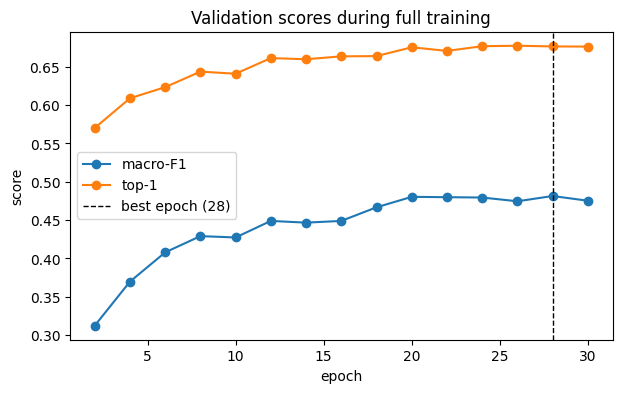

,macro_f1,top1,top3,loss_total,seconds,eval_seconds
epoch,,,,,,
2,0.312,0.570,0.740,11.859,518.139,72.923
4,0.370,0.609,0.777,9.352,518.324,68.529
6,0.408,0.624,0.790,8.205,518.334,68.462
8,0.429,0.644,0.805,7.508,517.776,68.443
10,0.427,0.641,0.806,6.807,518.301,68.421
12,0.449,0.661,0.814,6.379,517.506,68.279
14,0.447,0.660,0.819,5.958,517.646,69.469
16,0.449,0.664,0.823,5.693,518.155,66.712
18,0.467,0.664,0.824,5.415,517.455,66.071


In [17]:
SCORE_NAMES = {"macro_f1": "macro-F1", "top1": "top-1"}
history, best_epoch = full_run.history, full_run.final["run"]["best_epoch"]
if full_run.coverage:
    print(f"scenery swap: {full_run.coverage['with_mask']:,} of {full_run.coverage['photos']:,} "
          f"training photos ({full_run.coverage['share']:.1%}) have a usable "
          f"{full_run.coverage['mask_source']} mask")
fig, ax = plt.subplots(figsize=(7, 4))
for column, name in SCORE_NAMES.items():
    ax.plot(history["epoch"], history[column], marker="o", label=name)
ax.axvline(best_epoch, color="k", ls="--", lw=1, label=f"best epoch ({best_epoch})")
ax.set(title="Validation scores during full training", xlabel="epoch", ylabel="score")
ax.legend()
plt.show()
history.set_index("epoch")[["macro_f1", "top1", "top3", "loss_total", "seconds",
                            "eval_seconds"]].round(3)

### Verdicts

M3's final model, from the decision file the app ships with, next to the full model. A **false alarm**
is a snake that is neither WHO-listed nor a viper or elapid but is called dangerous.

In [18]:
M3_DECISION = REPO / "results/m3/final/H1_top1_s1/decision_metrics.json"


def verdict_row(report):
    m, fit = report["verdict_metrics"], report["recall_bound_fit"]
    low, high = report["intervals"]["who_dangerous_recall"]
    return {"WHO recall, calibration": fit["point_recall"],
            "  its lower bound": fit["lower_bound"],
            "WHO recall, validation": m["who_dangerous_recall"],
            "  95% interval": f"{low:.3f} to {high:.3f}",
            "false alarms, validation": m["false_alarm"],
            '"we don\'t know", validation': m["abstain_rate"],
            "unknown species flagged": report["u1"]["groups"]["all"]["flagged_at_tau"],
            "theta_conf": report["thresholds"]["theta_conf"],
            "no-snake cut-off": report["no_snake"].get("tau_snake")}


m3_decision = json.loads(M3_DECISION.read_text())
pd.DataFrame({"M3 final": verdict_row(m3_decision), RUN_ID: verdict_row(full_run.decision)}).map(
    lambda value: round(value, 3) if isinstance(value, float) else value)

,M3 final,M4_FULL
"WHO recall, calibration",0.966,0.968
its lower bound,0.952,0.956
"WHO recall, validation",0.948,0.94
95% interval,0.930 to 0.963,0.920 to 0.959
"false alarms, validation",0.311,0.178
"""we don't know"", validation",0.095,0.164
unknown species flagged,0.075,0.248
theta_conf,0.361,0.345
no-snake cut-off,0.102,0.102


### Species counts

The goal (G2) is at least 80 of the 158 measurable species at an F1 of 0.5 or above.

G2: 87 of 158 species at F1 0.5 or above, goal 80: passed


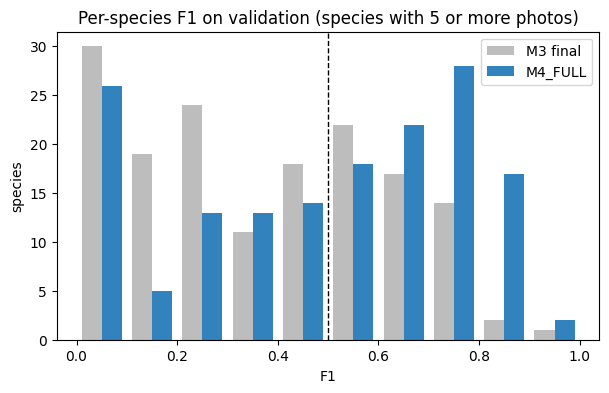

,M3 final,M4_FULL
measurable,158.000,158.000
f1_at_least_0.3,85.000,114.000
f1_at_least_0.5,56.000,87.000
f1_at_least_0.7,17.000,47.000
median_f1,0.336,0.552
f1_zero,18.000,23.000


In [19]:
G2_SPECIES = 80
reached = full_run.counts[RUN_ID]["f1_at_least_0.5"]
print(f"G2: {reached} of {full_run.counts[RUN_ID]['measurable']} species at F1 0.5 or above, goal "
      f"{G2_SPECIES}: {'passed' if reached >= G2_SPECIES else 'not passed'}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(list(full_run.f1_by_run.values()), bins=np.linspace(0, 1, 11),
        label=list(full_run.f1_by_run), color=["#bdbdbd", "#3182bd"])
ax.axvline(0.5, color="k", ls="--", lw=1)
ax.set(title="Per-species F1 on validation (species with 5 or more photos)", xlabel="F1",
       ylabel="species")
ax.legend()
plt.show()
pd.DataFrame(full_run.counts).round(3)

### Against B1

In [20]:
METRIC_NAMES = {"top1": "top-1", "macro_f1": "macro-F1 (G3 headline)",
                "macro_f1_m3_definition": "macro-F1, M3's whole-slice definition"}
g3 = full_run.g3
print(f"G3 on the 2022 slice: top-1 {g3['top1']}, macro-F1 {g3['macro_f1']}: "
      f"{'passed' if g3['passed'] else 'not passed'}")
table = []
for name, result in full_run.comparison.items():
    for metric, metric_name in METRIC_NAMES.items():
        row = {"photos": SLICES[name], "score": metric_name,
               **{model: result["scores"][model][metric]
                  for model in ("ours", "B1", "ours, closed set")}}
        for model in AGAINST_B1:
            interval = result["against_b1"][model][metric]
            row[f"{model} minus B1"] = (f"{interval['diff']:+.3f} ({interval['low']:+.3f} to "
                                        f"{interval['high']:+.3f})")
        table.append(row)
pd.DataFrame(table).set_index(["photos", "score"]).round(3)

G3 on the 2022 slice: top-1 lower, macro-F1 tied: not passed


ours     B1  \
photos                score                                                 
all validation photos top-1                                  0.724  0.801   
                      macro-F1 (G3 headline)                 0.723  0.739   
                      macro-F1, M3's whole-slice definition  0.690  0.653   
uploaded from 2022    top-1                                  0.723  0.788   
                      macro-F1 (G3 headline)                 0.713  0.719   
                      macro-F1, M3's whole-slice definition  0.679  0.637   

                                                             ours, closed set  \
photos                score                                                     
all validation photos top-1                                             0.779   
                      macro-F1 (G3 headline)                            0.729   
                      macro-F1, M3's whole-slice definition             0.659   
uploaded from 2022    top-1                                             0.775   
                      macro-F1 (G3 headline)                            0.718   
                      macro-F1, M3's whole-slice definition             0.653   

                                                                         ours minus B1  \
photos                score                                                              
all validation photos top-1                                  -0.078 (-0.098 to -0.058)   
                      macro-F1 (G3 headline)                 -0.017 (-0.034 to +0.002)   
                      macro-F1, M3's whole-slice definition  +0.037 (+0.019 to +0.055)   
uploaded from 2022    top-1                                  -0.065 (-0.083 to -0.047)   
                      macro-F1 (G3 headline)                 -0.006 (-0.024 to +0.016)   
                      macro-F1, M3's whole-slice definition  +0.043 (+0.024 to +0.066)   

                                                                     M3 final minus B1  \
photos                score                                                              
all validation photos top-1                                  -0.119 (-0.132 to -0.107)   
                      macro-F1 (G3 headline)                 -0.137 (-0.154 to -0.117)   
                      macro-F1, M3's whole-slice definition  -0.085 (-0.104 to -0.065)   
uploaded from 2022    top-1                                  -0.109 (-0.123 to -0.094)   
                      macro-F1 (G3 headline)                 -0.125 (-0.140 to -0.098)   
                      macro-F1, M3's whole-slice definition  -0.077 (-0.096 to -0.050)   

                                                            ours, predictions shuffled minus B1  
photos                score                                                                      
all validation photos top-1                                           -0.771 (-0.788 to -0.756)  
                      macro-F1 (G3 headline)                          -0.725 (-0.737 to -0.695)  
                      macro-F1, M3's whole-slice definition           -0.640 (-0.650 to -0.609)  
uploaded from 2022    top-1                                           -0.759 (-0.777 to -0.741)  
                      macro-F1 (G3 headline)                          -0.705 (-0.716 to -0.672)  
                      macro-F1, M3's whole-slice definition           -0.624 (-0.633 to -0.590)

### The scenery test

In [21]:
CONDITIONS = {"as_is": "as it is", "as_is_masked": "as it is, photos with a mask",
              "blanked": "snake blanked, scenery only", "swapped": "snake on another scenery"}
by_run = {"M3 final": json.loads(M3_ROBUSTNESS.read_text()), RUN_ID: full_run.r1}
gap, m3_gap = scenery_gap(full_run.r1), scenery_gap(by_run["M3 final"])
print(f"G1: top-1 falls by {gap:.3f} when the scenery is swapped, against {m3_gap:.3f} for M3; "
      f"goal {m3_gap / 2:.3f} or less: {'passed' if gap <= m3_gap / 2 else 'not passed'}")
pd.DataFrame({run: {text: report["conditions"][key]["top1"] for key, text in CONDITIONS.items()}
              for run, report in by_run.items()}).round(3)

G1: top-1 falls by 0.075 when the scenery is swapped, against 0.168 for M3; goal 0.084 or less: passed


,M3 final,M4_FULL
as it is,0.622,0.677
"as it is, photos with a mask",0.628,0.685
"snake blanked, scenery only",0.128,0.142
snake on another scenery,0.460,0.610


## 7. The non-snake test photos, scored once

The non-snake set's test split (notebook 19) has stayed locked until now. With the gate notebook 20 picked
(the detector's box, the segmenter's mask, or both must agree), its retrained weights and its thresholds,
fitted on calibration snakes to keep 99% of them, we count how many test photos would be called a snake. The
test split is scored only once: by this cell, or, when the cell cannot read its inputs, by a script run once
afterwards with the same gate and functions (see the note after the cell). The goal (G4) is at most 5%.

Both inputs are private outputs of other notebooks' runs on our account (`sg-m4-non-snake` and `sg-m4-gate`).
When the full pass did not finish, when either input can't be read here (not attached to this session, not run
yet, or another account), or when the gate comes from a smoke run, the cell does nothing and the split stays
locked; it can then run on its own later.

In [22]:
NON_SNAKE_KERNEL, GATE_KERNEL = "puneetbajajiitm/sg-m4-non-snake", "puneetbajajiitm/sg-m4-gate"
FALSE_SNAKE_GOAL, SEGMENTER_KIND = 0.05, "unet"


def optional_output(handle):
    try:
        return kernel_output(handle)
    except Exception as error:  # an optional input: not attached, not run yet, or not ours
        print(f"{handle} can't be read here ({type(error).__name__})")
        return None


negatives_root = optional_output(NON_SNAKE_KERNEL) if FULL_PASSED else None
gate_root = optional_output(GATE_KERNEL) if FULL_PASSED else None
gate_file = None if gate_root is None else next(gate_root.rglob("gate.json"), None)
gate = None if gate_file is None else json.loads(gate_file.read_text())
if not FULL_PASSED:
    print("the full pass did not finish: the non-snake test split stays locked")
elif negatives_root is None or gate is None:
    print("no non-snake set or no gate: the non-snake test split stays locked")
elif gate.get("limit") is not None or gate.get("epochs") is not None:
    print("the gate comes from a smoke run: the non-snake test split stays locked")
else:
    from ultralytics import YOLO

    detector = YOLO(str(found(gate_root, gate["detector"])))
    segmenter_dir = Path(tempfile.mkdtemp())  # Segmenter reads <folder>/segmenter.pt
    shutil.copy2(found(gate_root, gate["segmenter"]), segmenter_dir / "segmenter.pt")
    segmenter = front_end.Segmenter(SEGMENTER_KIND, segmenter_dir)
    negatives = found(negatives_root, "manifest.csv").parent
    manifest = pd.read_csv(negatives / "manifest.csv")
    test = manifest[manifest["split"] == "test"].reset_index(drop=True)
    frame = pd.DataFrame({"path": test["file"], "is_snake": False,
                          "image_file": [str(negatives / name) for name in test["file"]]})
    scores = front_end.gate_scores(frame, detector, segmenter)
    rule, thresholds = gate["rule"], gate["thresholds"]
    rate = front_end.false_snake_rate(scores, rule, thresholds)
    called = pd.Series(front_end.gate_calls(scores, rule, thresholds),
                       index=test["category"].to_numpy())
    by_category = called.groupby(level=0).mean()
    write_json(WORK / "full" / "non_snake_test.json",
               {"split": "test", "photos": len(scores), "gate": gate, "false_snake_rate": rate,
                "by_category": by_category.to_dict()})
    print(f"G4: {rate:.1%} of {len(scores):,} non-snake test photos called a snake, goal at most "
          f"{FALSE_SNAKE_GOAL:.0%}: {'passed' if rate <= FALSE_SNAKE_GOAL else 'not passed'}")
    display(by_category.round(3).to_frame("called a snake"))

puneetbajajiitm/sg-m4-non-snake can't be read here (BackendError)
puneetbajajiitm/sg-m4-gate can't be read here (BackendError)
no non-snake set or no gate: the non-snake test split stays locked


*Note added after the run:* the cell above could not read `sg-m4-non-snake` or `sg-m4-gate` in this session
(both printed `BackendError`), as in the other two full runs, so the non-snake test split stayed locked here.
It was scored once afterwards, on the team laptop's CPU, by `scripts/score_non_snake_test.py`, with the gate
in `results/m4/gate/gate.json` (rule "both", the cut-offs notebook 20 fitted on calibration snakes) and the
same functions as the cell above (`front_end.gate_scores`, `false_snake_rate` and `gate_calls`). The photos
were re-made from the manifest's source urls by `scripts/fetch_non_snake_test.py` and matched to the
manifest's sizes and pHashes; no model had seen them before that one scoring. The result is in
`results/m4/gate/non_snake_test.json`: 170 of the 600 test photos (28.3%) are called a snake, against the goal
of at most 5%, so G4 is not met.

## What we found

This run trained the A1 recipe (the detector's box crop, the scenery swapped half the time with SAM masks) on
all 49,782 training photos; the best epoch was 28 of 30. Every number below is read from this run's files in
`results/m4/full/A1/`. On all 17,151 validation photos, top-1 is 0.677 and macro-F1 0.481 (M3's final model:
0.622 and 0.367).

- **G1, the scenery: passed.** On the 15,977 validation photos with a mask, top-1 falls from 0.685 to 0.610
  when the snake is moved onto another scenery, a gap of 0.075 against M3's 0.168; the goal is 0.084 or less
  (`robustness_metrics.json`).
- **G2, the species: passed.** 87 of the 158 measurable species reach a validation F1 of 0.5, against 56 for
  M3; the goal is 80 (`per_class_counts.json`).
- **G3, against B1: not passed.** On the 11,931 photos of B1's 62 species in the 2022 slice, our top-1 is
  lower (-0.065, -0.083 to -0.047) and our macro-F1 tied (-0.006, -0.024 to +0.016). Made to answer with one
  of B1's species (the closed set, reported and not judged), top-1 is 0.775 against B1's 0.788 (`b1_62.json`).
- **Safety and the verdicts.** WHO recall on calibration keeps a lower bound of 0.956 (it must be 0.95 or
  more); on validation it is 0.940 (0.920 to 0.959), against 0.948 for M3. False alarms on validation are
  0.178 (M3 0.311), "we don't know" 0.164 (M3 0.095), and unknown species flagged 0.248 (M3 0.075)
  (`decision_metrics.json`).
- **G4** could not be scored in this session; see the note under section 7.